# Train a CNN on Imagenette: larger images, fewer classes

On CIFAR-100 (32 × 32 pixels, 100 classes), SDM formed **no region** on all 100 classes ([notebook 05](05_sdm_resnet18_cal100.ipynb)), and on the 56 classes the ResNet handles well, a high softmax threshold still did at least as well ([notebook 07](07_sdm_resnet18_cal100_selected_classes.ipynb)). Here we ask whether that changes on **higher-resolution images**.

**Imagenette** is a 10-class subset of ImageNet, released by fast.ai: tench, English springer, cassette player, chain saw, church, French horn, garbage truck, gas pump, golf ball and parachute. We use the 160-pixel version (shorter side 160 pixels), about **950 training images per class**.

This notebook follows [notebook 04](04_cifar100_resnet18_cal100.ipynb) step by step: same ResNet-18 (with an input layer suited to larger images), same training recipe, same temperature scaling and abstention thresholds. The model is **trained from scratch**: the Imagenette images come from ImageNet itself, so an ImageNet-pretrained model would already have seen them. [Notebook 09](09_sdm_resnet18_imagenette.ipynb) then applies SDM.

**Running time:** about 2 minutes to decode the images on the first run (cached in `data/` afterwards) and roughly 30–60 minutes of training on an Apple-silicon or NVIDIA GPU. Set `EPOCHS = 2` for a quick smoke test.

## 1. Import our tools and choose settings

As in notebook 04, we pick the fastest available device: an NVIDIA GPU (`cuda`), the Apple-silicon GPU (`mps`), or the CPU.

- Images are stored at **144 × 144** pixels. Training uses a random **128 × 128** window of each image; evaluation uses the center 128 × 128 window.
- `RESOLUTION = 32` reruns the whole notebook at CIFAR resolution: the same images, splits and framing, stored at 36 × 36 and seen as 32 × 32 windows. Files are saved under `imagenette32px_resnet18`, so the 128-pixel run is kept. Comparing the two separates the effect of resolution from the effect of the task (notebook 09, section 8).
- The calibration split is larger than in notebook 04 relative to the number of classes: **200 images per class**, which gives SDM's per-class rule room for a few misses at every α.

In [1]:
from pathlib import Path
import hashlib
import tarfile
import time
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image

SEED = 42
EPOCHS = 40            # set to 2 for a quick smoke test
BATCH_SIZE = 128
MAX_LR = 0.1           # peak learning rate of the one-cycle schedule
WEIGHT_DECAY = 5e-4
VAL_PER_CLASS = 50     # 50 images x 10 classes = 500 validation images
CAL_PER_CLASS = 200    # 200 images x 10 classes = 2,000 calibration images
RESOLUTION = 128       # the network sees RESOLUTION x RESOLUTION windows; set to 32 to rerun at CIFAR resolution
CROP_SIZE = RESOLUTION
STORE_SIZE = RESOLUTION * 9 // 8  # images are kept 1/8 larger (144 for 128, 36 for 32), so the random crop can shift them
STEM = "imagenet" if RESOLUTION >= 64 else "cifar"  # input layer: see section 5
TARGET_ACCURACY = 0.95 # accuracy we want on the images the model chooses to answer
EVALUATE_TEST = False  # leave False until the model is final
MODEL_NAME = "imagenette_resnet18" if RESOLUTION == 128 else f"imagenette{RESOLUTION}px_resnet18"  # prefix of every file saved to outputs/

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

torch.manual_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print(f"PyTorch {torch.__version__}, training on: {device}")

PyTorch 2.5.1, training on: mps


## 2. Find and load the data

The first run downloads the archive (about 95 MB) into `data/`, checks it against the SHA-256 fingerprint recorded here, and unpacks it. fast.ai does not publish a checksum, so the fingerprint is the one of the archive we downloaded when writing this notebook; if fast.ai ever changes the file, the check fails instead of silently training on different data.

Decoding about 13,000 JPEG files takes a couple of minutes, so the decoded 144 × 144 images are cached in `data/imagenette2-160_144px.npz` (about 800 MB, ignored by Git). Each image is resized so its shorter side is 144 pixels, then cut to its central square. A few images are grayscale; they are converted to three color channels.

Imagenette's own `val` folder plays the role of the official **test** set. We split our validation and calibration images out of its `train` folder, as notebook 04 does for CIFAR-100.

In [2]:
DATA_DIR = Path("../data")  # the repository's data/ folder
ARCHIVE_URL = "https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-160.tgz"
ARCHIVE_SHA256 = "64d0c4859f35a461889e0147755a999a48b49bf38a7e0f9bd27003f10db02fe5"
archive_path = DATA_DIR / "imagenette2-160.tgz"
data_path = DATA_DIR / "imagenette2-160"
cache_path = DATA_DIR / f"imagenette2-160_{STORE_SIZE}px.npz"

# First run only: download the archive, check it, and unpack it.
if not data_path.exists():
    if not archive_path.exists():
        urllib.request.urlretrieve(ARCHIVE_URL, archive_path)
    assert hashlib.sha256(archive_path.read_bytes()).hexdigest() == ARCHIVE_SHA256, f"{archive_path} is not the expected file; delete it and rerun"
    with tarfile.open(archive_path) as archive:
        archive.extractall(DATA_DIR, filter="data")

# ImageNet identifiers of the 10 classes, in the folder (sorted) order used as labels.
CLASS_NAMES = {
    "n01440764": "tench", "n02102040": "English_springer", "n02979186": "cassette_player",
    "n03000684": "chain_saw", "n03028079": "church", "n03394916": "French_horn",
    "n03417042": "garbage_truck", "n03425413": "gas_pump", "n03445777": "golf_ball", "n03888257": "parachute",
}
wnids = sorted(CLASS_NAMES)
for name in ["train", "val"]:
    assert sorted(folder.name for folder in (data_path / name).iterdir() if folder.is_dir()) == wnids, f"unexpected class folders in {data_path / name}"
class_names = [CLASS_NAMES[wnid] for wnid in wnids]
print("Data ready in", data_path)

Data ready in ../data/imagenette2-160


In [3]:
def load_image(path, size=STORE_SIZE):
    # Shorter side to `size` pixels, then the central square; (color channel, height, width) as PyTorch expects.
    image = Image.open(path).convert("RGB")
    scale = size / min(image.size)
    image = image.resize((max(size, round(image.width * scale)), max(size, round(image.height * scale))), Image.BICUBIC)
    left, top = (image.width - size) // 2, (image.height - size) // 2
    return np.asarray(image.crop((left, top, left + size, top + size))).transpose(2, 0, 1)


def load_split(name):
    files = sorted(data_path.glob(f"{name}/*/*.JPEG"))
    labels = np.array([wnids.index(file.parent.name) for file in files])
    return np.stack([load_image(file) for file in files]), labels, np.array([str(file.relative_to(data_path)) for file in files])


if cache_path.exists():
    with np.load(cache_path) as cache:
        all_images, all_labels, all_files = cache["train_images"], cache["train_labels"], cache["train_files"]
        x_test, y_test, test_files = cache["test_images"], cache["test_labels"], cache["test_files"]
    print("Loaded decoded images from", cache_path)
else:
    start = time.time()
    all_images, all_labels, all_files = load_split("train")
    x_test, y_test, test_files = load_split("val")
    np.savez(cache_path, train_images=all_images, train_labels=all_labels, train_files=all_files,
             test_images=x_test, test_labels=y_test, test_files=test_files)
    print(f"Decoded and cached the images in {time.time() - start:.0f}s:", cache_path)

assert len(all_images) == 9469 and len(x_test) == 3925, "unexpected number of images; delete the data and rerun"
print(f"{len(all_images):,} training-folder images, {len(x_test):,} test images, shape {all_images.shape[1:]}, {len(class_names)} classes")
pd.Series(np.bincount(all_labels), index=class_names, name="training-folder images").to_frame().T

Loaded decoded images from ../data/imagenette2-160_144px.npz
9,469 training-folder images, 3,925 test images, shape (3, 144, 144), 10 classes


,tench,English_springer,cassette_player,chain_saw,church,French_horn,garbage_truck,gas_pump,golf_ball,parachute
training-folder images,963,955,993,858,941,956,961,931,951,960


Let's look at a few images per class.

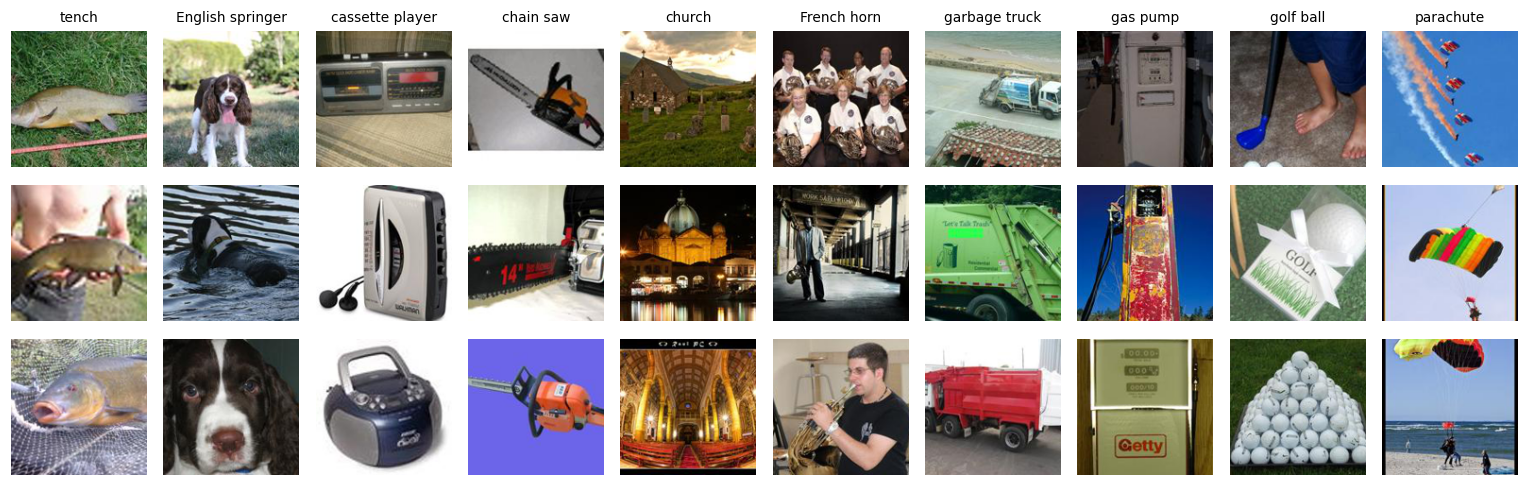

In [4]:
fig, axes = plt.subplots(3, 10, figsize=(14, 4.6))
rng = np.random.default_rng(SEED)
for column, class_id in enumerate(range(len(class_names))):
    for row, index in enumerate(rng.choice(np.flatnonzero(all_labels == class_id), size=3, replace=False)):
        axes[row, column].imshow(all_images[index].transpose(1, 2, 0))
        axes[row, column].axis("off")
    axes[0, column].set_title(class_names[class_id].replace("_", " "), fontsize=9)
plt.tight_layout()
plt.show()

## 3. Split the data: train, validation, calibration

The same stratified split as notebook 04 (within each class, shuffle with seed 42), with no image in more than one split:

| split | images | job |
|---|---|---|
| **training** | about 7,000 | the network learns its weights from these |
| **validation** | 500 | watch training and report results the model and its settings were not fitted on |
| **calibration** | 2,000 | fit the temperature, the abstention threshold, and (in notebook 09) SDM |
| **test** (Imagenette `val`) | 3,925 | final check only, in the optional last section |

Validation has only 50 images per class. That is enough for overall numbers, but per-class numbers on validation are noisy.

In [5]:
rng = np.random.default_rng(SEED)
train_idx, val_idx, cal_idx = [], [], []
for class_id in range(len(class_names)):
    shuffled = rng.permutation(np.flatnonzero(all_labels == class_id))
    val_idx.extend(shuffled[:VAL_PER_CLASS])
    cal_idx.extend(shuffled[VAL_PER_CLASS : VAL_PER_CLASS + CAL_PER_CLASS])
    train_idx.extend(shuffled[VAL_PER_CLASS + CAL_PER_CLASS :])
train_idx, val_idx, cal_idx = np.array(train_idx), np.array(val_idx), np.array(cal_idx)
assert not (set(train_idx) & set(val_idx) or set(train_idx) & set(cal_idx) or set(val_idx) & set(cal_idx))

x_train, y_train = all_images[train_idx], all_labels[train_idx]
x_val, y_val = all_images[val_idx], all_labels[val_idx]
x_cal, y_cal = all_images[cal_idx], all_labels[cal_idx]

pd.Series({
    "training images": len(x_train),
    "validation images": len(x_val),
    "calibration images": len(x_cal),
    "training images per class (min / max)": f"{np.bincount(y_train).min()} / {np.bincount(y_train).max()}",
    "images per class (val / cal)": f"{np.bincount(y_val).min()} / {np.bincount(y_cal).min()}",
}, name="split").to_frame()

,split
training images,6969
validation images,500
calibration images,2000
training images per class (min / max),608 / 743
images per class (val / cal),50 / 200


## 4. Prepare the pixels: normalization and augmentation

**Normalization** is the same as notebook 04: shift and scale each color channel to mean 0 and standard deviation 1, with statistics from the training split only.

**Augmentation.** Every training batch is changed a little:

- **random crop**: a random 128 × 128 window of the 144 × 144 image (a shift of up to 16 pixels),
- **horizontal flip**: mirror half the images left to right.

For validation, calibration and test images the network always sees the **central** 128 × 128 window, so their predictions are deterministic.

In [6]:
channel_mean = torch.tensor(x_train.mean(axis=(0, 2, 3)) / 255, dtype=torch.float32, device=device).view(1, 3, 1, 1)
channel_std = torch.tensor(x_train.std(axis=(0, 2, 3)) / 255, dtype=torch.float32, device=device).view(1, 3, 1, 1)

def to_device(images, labels):
    return torch.from_numpy(images).to(device), torch.from_numpy(labels).long().to(device)

train_images, train_labels = to_device(x_train, y_train)
val_images, val_labels = to_device(x_val, y_val)
cal_images, cal_labels = to_device(x_cal, y_cal)

def normalize(batch):
    return (batch.float() / 255 - channel_mean) / channel_std

def augment(batch, size=CROP_SIZE):
    # Random crop: pick a random size x size window for each image.
    n, _, h, w = batch.shape
    top = torch.randint(0, h - size + 1, (n, 1, 1), device=batch.device)
    left = torch.randint(0, w - size + 1, (n, 1, 1), device=batch.device)
    rows = top + torch.arange(size, device=batch.device).view(1, size, 1)
    cols = left + torch.arange(size, device=batch.device).view(1, 1, size)
    batch = batch[torch.arange(n, device=batch.device).view(n, 1, 1), :, rows, cols].permute(0, 3, 1, 2)
    # Horizontal flip for a random half of the batch.
    flip = torch.rand(n, 1, 1, 1, device=batch.device) < 0.5
    return torch.where(flip, batch.flip(3), batch)

def center_crop(batch, size=CROP_SIZE):
    offset = (batch.shape[-1] - size) // 2
    return batch[..., offset : offset + size, offset : offset + size]

print("channel mean:", channel_mean.flatten().cpu().numpy().round(3))
print("channel std: ", channel_std.flatten().cpu().numpy().round(3))

channel mean: [0.465 0.458 0.43 ]
channel std:  [0.277 0.273 0.295]


Let's check the augmentation by eye. Each row shows one training image's central window (left) and five random augmented versions of it.

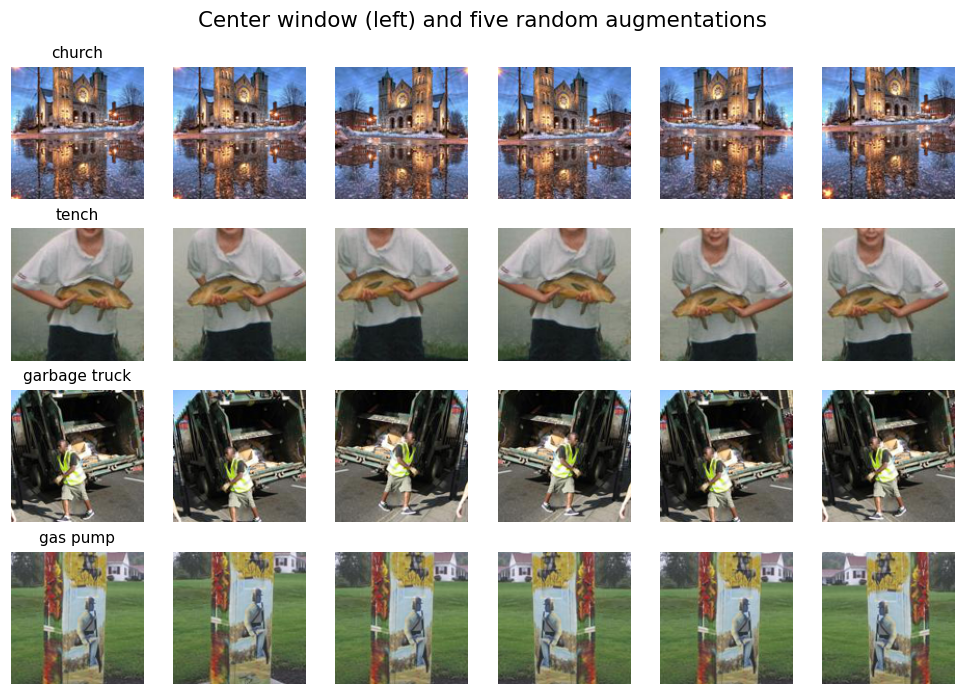

In [7]:
def show(image_tensor):
    # Undo normalization and move channels last for Matplotlib.
    image = image_tensor * channel_std[0] + channel_mean[0]
    return image.clamp(0, 1).permute(1, 2, 0).cpu().numpy()

examples = torch.from_numpy(np.random.default_rng(SEED).choice(len(x_train), size=4, replace=False)).to(device)
fig, axes = plt.subplots(4, 6, figsize=(9, 6.4))
for row, index in zip(axes, examples):
    original = train_images[index : index + 1]
    row[0].imshow(show(normalize(center_crop(original))[0]))
    row[0].set_title(class_names[train_labels[index]].replace("_", " "), fontsize=10)
    for ax in row[1:]:
        ax.imshow(show(normalize(augment(original))[0]))
    for ax in row:
        ax.axis("off")
fig.suptitle("Center window (left) and five random augmentations", fontsize=14)
plt.tight_layout()
plt.show()

## 5. Build the CNN

The same **ResNet-18** as notebook 04 (residual blocks, batch normalization, four stages of 64, 128, 256 and 512 filters), with one change for larger images: the **input layer** is the standard ImageNet one, a 7 × 7 convolution with stride 2 followed by a 3 × 3 max-pool. It shrinks a 128 × 128 image to 32 × 32 before the residual stages, so the stages then work at the same sizes as on CIFAR: 32 × 32 → 16 × 16 → 8 × 8 → 4 × 4.

At `RESOLUTION = 32` the network keeps notebook 04's input layer (one 3 × 3 convolution, no shrinking), so the residual stages see exactly the same sizes as in the 128-pixel run. Only the detail in the image differs.

The **embedding** is still the 512-number vector after global average pooling, so the SDM code in notebook 09 is unchanged.

In [8]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.shortcut = nn.Identity()
        if stride != 1 or in_channels != out_channels:
            # Match the shape of the input so it can be added to the output.
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x))


class ImageNetResNet(nn.Module):
    # Notebook 04's CifarResNet. stem="imagenet" uses the ImageNet input layer (7 x 7 convolution, stride 2, then a 3 x 3 max-pool);
    # stem="cifar" keeps notebook 04's 3 x 3 convolution, for 32 x 32 images.
    def __init__(self, num_classes=10, widths=(64, 128, 256, 512), stem="imagenet"):
        super().__init__()
        if stem == "imagenet":
            self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 7, stride=2, padding=3, bias=False), nn.BatchNorm2d(widths[0]), nn.ReLU(),
                                      nn.MaxPool2d(3, stride=2, padding=1))
        else:
            self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 3, padding=1, bias=False), nn.BatchNorm2d(widths[0]), nn.ReLU())
        stages, in_channels = [], widths[0]
        for i, width in enumerate(widths):
            stride = 1 if i == 0 else 2
            stages.append(nn.Sequential(ResidualBlock(in_channels, width, stride), ResidualBlock(width, width)))
            in_channels = width
        self.stages = nn.Sequential(*stages)
        self.classifier = nn.Linear(widths[-1], num_classes)

    def embed(self, x):
        # The 512-dimensional feature vector before the final layer.
        return F.adaptive_avg_pool2d(self.stages(self.stem(x)), 1).flatten(1)

    def forward(self, x):
        return self.classifier(self.embed(x))


model = ImageNetResNet(num_classes=len(class_names), stem=STEM).to(device)
print(f"{sum(p.numel() for p in model.parameters()):,} trainable parameters")
with torch.no_grad():
    print("logits shape for 2 images:", tuple(model(normalize(center_crop(train_images[:2]))).shape))

11,181,642 trainable parameters
logits shape for 2 images: (2, 10)


## 6. Set up training

Exactly as notebook 04: cross-entropy without label smoothing (it would change what the softmax confidence means), SGD with Nesterov momentum and weight decay, and the one-cycle learning-rate schedule. We keep the model from the **final epoch**, so validation is never used to pick a checkpoint.

In [9]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=MAX_LR, momentum=0.9, nesterov=True, weight_decay=WEIGHT_DECAY)
steps_per_epoch = (len(train_images) + BATCH_SIZE - 1) // BATCH_SIZE
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=MAX_LR, epochs=EPOCHS, steps_per_epoch=steps_per_epoch)


def train_one_epoch():
    model.train()
    order = torch.randperm(len(train_images), device=device)
    total_loss = total_correct = 0
    for start in range(0, len(order), BATCH_SIZE):
        batch = order[start : start + BATCH_SIZE]
        inputs, targets = normalize(augment(train_images[batch])), train_labels[batch]
        logits = model(inputs)
        loss = criterion(logits, targets)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        scheduler.step()
        total_loss += loss.item() * len(batch)
        total_correct += (logits.argmax(1) == targets).sum().item()
    return total_loss / len(order), total_correct / len(order)


@torch.no_grad()
def predict(images, batch_size=250):
    # Returns logits and embeddings for every image (central window, no augmentation), on the CPU.
    model.eval()
    logits, embeddings = [], []
    for start in range(0, len(images), batch_size):
        features = model.embed(normalize(center_crop(images[start : start + batch_size])))
        embeddings.append(features.cpu())
        logits.append(model.classifier(features).cpu())
    return torch.cat(logits), torch.cat(embeddings)

## 7. Train

Each epoch is one pass over the training images. Training accuracy is measured on *augmented* images, so it can sit below validation accuracy early on.

In [10]:
history = []
for epoch in range(1, EPOCHS + 1):
    start = time.time()
    train_loss, train_acc = train_one_epoch()
    val_logits, _ = predict(val_images)
    val_loss = F.cross_entropy(val_logits, val_labels.cpu()).item()
    val_acc = (val_logits.argmax(1) == val_labels.cpu()).float().mean().item()
    history.append({"epoch": epoch, "train loss": train_loss, "val loss": val_loss, "train acc": train_acc, "val acc": val_acc})
    print(f"epoch {epoch:2d}/{EPOCHS}  train loss {train_loss:.3f}  acc {train_acc:.1%}  |  "
          f"val loss {val_loss:.3f}  acc {val_acc:.1%}  |  {time.time() - start:.0f}s")
history = pd.DataFrame(history).set_index("epoch")

epoch  1/40  train loss 1.763  acc 39.3%  |  val loss 3.263  acc 31.2%  |  12s
epoch  2/40  train loss 1.202  acc 60.9%  |  val loss 2.720  acc 38.8%  |  12s
epoch  3/40  train loss 1.057  acc 65.1%  |  val loss 2.009  acc 37.8%  |  12s
epoch  4/40  train loss 1.004  acc 67.7%  |  val loss 1.430  acc 54.6%  |  12s
epoch  5/40  train loss 0.917  acc 70.9%  |  val loss 2.340  acc 45.4%  |  12s
epoch  6/40  train loss 0.881  acc 72.2%  |  val loss 1.338  acc 56.4%  |  12s
epoch  7/40  train loss 0.798  acc 74.5%  |  val loss 1.904  acc 51.6%  |  12s
epoch  8/40  train loss 0.805  acc 74.4%  |  val loss 1.040  acc 66.8%  |  12s
epoch  9/40  train loss 0.720  acc 77.6%  |  val loss 1.079  acc 68.4%  |  12s
epoch 10/40  train loss 0.665  acc 78.4%  |  val loss 1.490  acc 57.0%  |  12s
epoch 11/40  train loss 0.650  acc 79.0%  |  val loss 1.286  acc 67.8%  |  15s
epoch 12/40  train loss 0.566  acc 81.7%  |  val loss 1.931  acc 61.8%  |  13s
epoch 13/40  train loss 0.523  acc 82.9%  |  val los

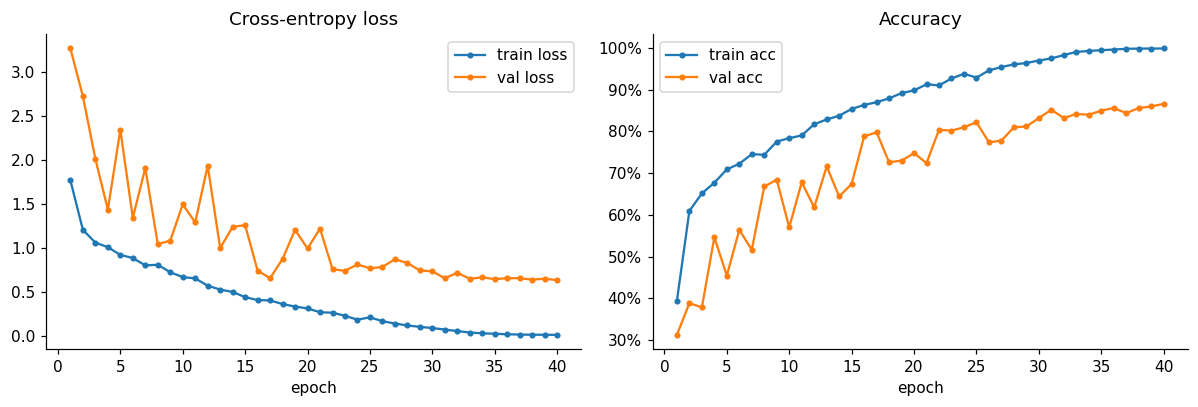

In [11]:
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(11, 3.8))
history[["train loss", "val loss"]].plot(ax=ax_loss, marker=".")
ax_loss.set_title("Cross-entropy loss")
history[["train acc", "val acc"]].plot(ax=ax_acc, marker=".")
ax_acc.set_title("Accuracy")
ax_acc.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
for ax in (ax_loss, ax_acc):
    ax.set_xlabel("epoch")
plt.tight_layout()
plt.show()

## 8. How accurate is the model?

Besides validation accuracy, we measure accuracy on the **training images without augmentation**. On CIFAR-100 the ResNet was right on 99.3% of its training images: it had nearly memorized them, which makes SDM's comparison of new images with training images less informative. The gap between training and validation accuracy tells us whether the same happens here.

In [12]:
val_logits, val_embeddings = predict(val_images)
train_logits, _ = predict(train_images)
y_true = val_labels.cpu().numpy()
probs = val_logits.softmax(1).numpy()
y_pred = probs.argmax(1)
confidence = probs.max(1)
correct = y_pred == y_true

pd.Series({
    "training accuracy (no augmentation)": f"{(train_logits.argmax(1).numpy() == y_train).mean():.1%}",
    "validation top-1 accuracy": f"{correct.mean():.1%}",
    "validation mean confidence": f"{confidence.mean():.1%}",
}, name="ResNet-18").to_frame()

,ResNet-18
training accuracy (no augmentation),100.0%
validation top-1 accuracy,86.6%
validation mean confidence,93.9%


With only 10 classes we can look at the whole **confusion table**: where the validation images of each class ended up.

In [13]:
confusion = pd.crosstab(pd.Categorical(np.array(class_names)[y_true], class_names), pd.Categorical(np.array(class_names)[y_pred], class_names),
                        normalize="index", dropna=False)
confusion.rename_axis(index="true class", columns="predicted").style.format("{:.0%}").background_gradient(cmap="Blues", axis=None)

predicted,tench,English_springer,cassette_player,chain_saw,church,French_horn,garbage_truck,gas_pump,golf_ball,parachute
true class,,,,,,,,,,
tench,94%,2%,0%,2%,0%,0%,0%,0%,0%,2%
English_springer,2%,82%,0%,4%,2%,2%,0%,2%,2%,4%
cassette_player,0%,0%,86%,6%,0%,0%,4%,2%,2%,0%
chain_saw,0%,8%,0%,78%,2%,2%,6%,0%,0%,4%
church,0%,2%,0%,2%,86%,2%,0%,2%,0%,6%
French_horn,0%,0%,0%,14%,2%,84%,0%,0%,0%,0%
garbage_truck,0%,0%,0%,0%,4%,0%,94%,0%,0%,2%
gas_pump,0%,0%,2%,2%,2%,2%,0%,90%,2%,0%
golf_ball,0%,0%,2%,4%,0%,0%,2%,2%,88%,2%


## 9. Is the model calibrated?

The same reliability diagram and expected calibration error (ECE, 15 bins) as notebook 04. Bars below the diagonal mean the model is overconfident.

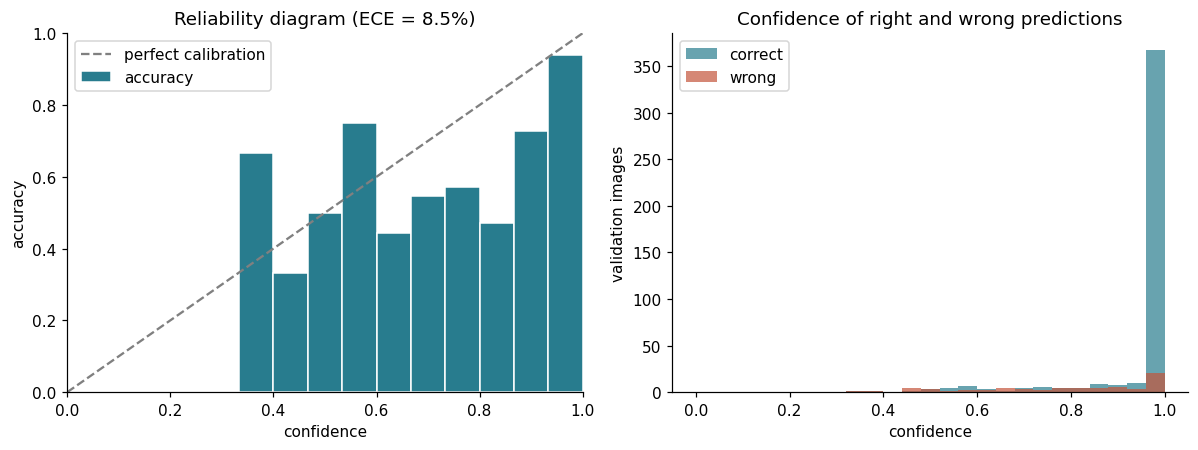

In [14]:
def calibration_bins(confidence, correct, n_bins=15):
    edges = np.linspace(0, 1, n_bins + 1)
    which = np.clip(np.digitize(confidence, edges[1:-1]), 0, n_bins - 1)
    table = pd.DataFrame({"bin": which, "confidence": confidence, "correct": correct}).groupby("bin").agg(
        count=("correct", "size"), confidence=("confidence", "mean"), accuracy=("correct", "mean"))
    ece = (table["count"] / len(confidence) * (table["confidence"] - table["accuracy"]).abs()).sum()
    return table, edges, ece


def reliability_diagram(ax, confidence, correct, title):
    table, edges, ece = calibration_bins(confidence, correct)
    ax.bar(edges[table.index], table["accuracy"], width=edges[1], align="edge", color="#287c8e", edgecolor="white", label="accuracy")
    ax.plot([0, 1], [0, 1], "--", color="gray", label="perfect calibration")
    ax.set(xlabel="confidence", ylabel="accuracy", title=f"{title} (ECE = {ece:.1%})", xlim=(0, 1), ylim=(0, 1))
    ax.legend(loc="upper left")


fig, (ax_rel, ax_hist) = plt.subplots(1, 2, figsize=(11, 4.2))
reliability_diagram(ax_rel, confidence, correct, "Reliability diagram")
bins = np.linspace(0, 1, 26)
ax_hist.hist(confidence[correct], bins=bins, alpha=0.7, color="#287c8e", label="correct")
ax_hist.hist(confidence[~correct], bins=bins, alpha=0.7, color="#c4553a", label="wrong")
ax_hist.set(xlabel="confidence", ylabel="validation images", title="Confidence of right and wrong predictions")
ax_hist.legend()
plt.tight_layout()
plt.show()

## 10. Temperature scaling

As in notebook 04: one temperature *T*, chosen on the **calibration set** by minimizing the negative log-likelihood, divides every logit before the softmax. Accuracy does not change; only the confidence does. Then we check it on validation.

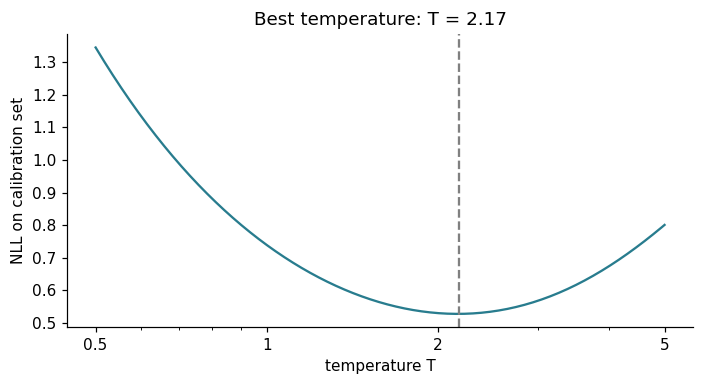

In [15]:
cal_logits, cal_embeddings = predict(cal_images)
cal_targets = cal_labels.cpu()

temperatures = np.exp(np.linspace(np.log(0.5), np.log(5), 200))
cal_nll = np.array([F.cross_entropy(cal_logits / t, cal_targets).item() for t in temperatures])
TEMPERATURE = float(temperatures[cal_nll.argmin()])

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(temperatures, cal_nll, color="#287c8e")
ax.axvline(TEMPERATURE, ls="--", color="gray")
ax.set(xscale="log", xlabel="temperature T", ylabel="NLL on calibration set",
       title=f"Best temperature: T = {TEMPERATURE:.2f}")
ax.set_xticks([0.5, 1, 2, 5], labels=["0.5", "1", "2", "5"])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
plt.tight_layout()
plt.show()

,accuracy,mean confidence,ECE,NLL
validation set,,,,
before (T = 1),86.6%,93.9%,8.5%,0.630
after (T = 2.17),86.6%,84.9%,3.5%,0.458


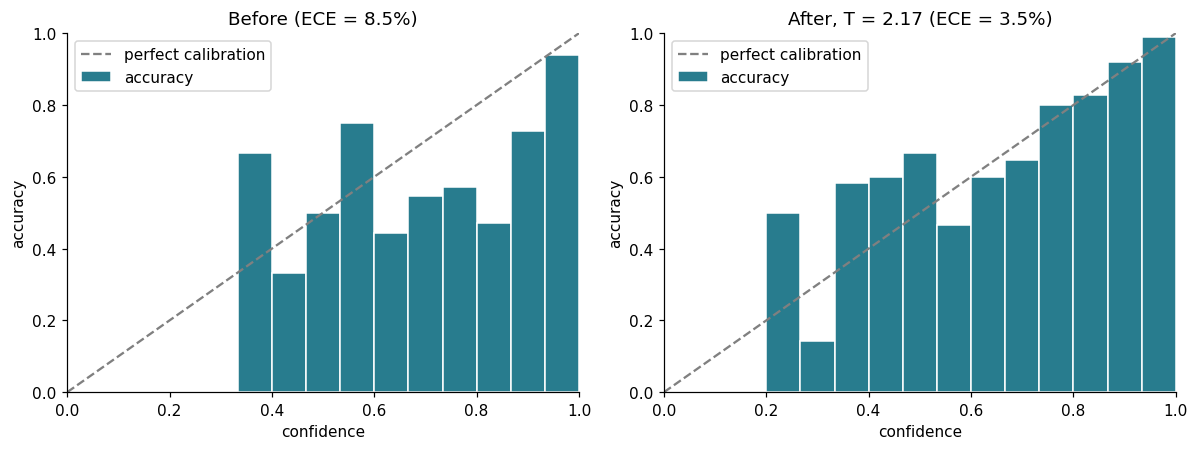

In [16]:
def softmax_confidence(logits, temperature=1.0):
    probs = (logits / temperature).softmax(1)
    return probs.max(1).values.numpy()

scaled_confidence = softmax_confidence(val_logits, TEMPERATURE)
before = calibration_bins(confidence, correct)[2], F.cross_entropy(val_logits, val_labels.cpu()).item()
after = calibration_bins(scaled_confidence, correct)[2], F.cross_entropy(val_logits / TEMPERATURE, val_labels.cpu()).item()

display(pd.DataFrame({
    "accuracy": [f"{correct.mean():.1%}"] * 2,
    "mean confidence": [f"{confidence.mean():.1%}", f"{scaled_confidence.mean():.1%}"],
    "ECE": [f"{before[0]:.1%}", f"{after[0]:.1%}"],
    "NLL": [f"{before[1]:.3f}", f"{after[1]:.3f}"],
}, index=["before (T = 1)", f"after (T = {TEMPERATURE:.2f})"]).rename_axis("validation set"))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
reliability_diagram(axes[0], confidence, correct, "Before")
reliability_diagram(axes[1], scaled_confidence, correct, f"After, T = {TEMPERATURE:.2f}")
plt.tight_layout()
plt.show()

## 11. Selective prediction: answer only when confident

The same two-step rule as notebook 04: **choose** the confidence threshold on the calibration set so the answered images are at least 95% correct (plain), or so the lower end of the 95% Wilson interval is at least 95% (conservative), then **check** it on validation. The coverage at 95% selective accuracy is the baseline SDM has to beat in notebook 09.

In [17]:
def wilson_interval(successes, n, z=1.96):
    # 95% confidence interval for a proportion; works on numbers or arrays.
    successes, n = np.asarray(successes, dtype=float), np.asarray(n, dtype=float)
    p = successes / n
    denominator = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denominator
    half_width = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denominator
    return center - half_width, center + half_width


def selective_curve(confidence, correct):
    # Coverage and selective accuracy when answering the k most confident images, for every k.
    order = np.argsort(-confidence)
    answered = np.arange(1, len(order) + 1)
    hits = np.cumsum(correct[order])
    return order, answered, hits


def choose_threshold(confidence, correct, target, conservative=False):
    order, answered, hits = selective_curve(confidence, correct)
    score = wilson_interval(hits, answered)[0] if conservative else hits / answered
    meets = np.flatnonzero(score >= target)
    return None if len(meets) == 0 else float(confidence[order][meets.max()])


def check_threshold(threshold, confidence, correct):
    answered = confidence >= threshold if threshold is not None else np.zeros(len(confidence), bool)
    n, k = answered.sum(), correct[answered].sum()
    low, high = wilson_interval(k, n) if n else (np.nan, np.nan)
    return {
        "threshold": "none reaches target" if threshold is None else f"{threshold:.3f}",
        "coverage": f"{answered.mean():.1%}",
        "images answered": int(n),
        "selective accuracy": f"{k / n:.1%}" if n else "-",
        "95% interval": f"{low:.1%} – {high:.1%}" if n else "-",
    }


cal_confidence = softmax_confidence(cal_logits, TEMPERATURE)
cal_correct = cal_logits.argmax(1).numpy() == y_cal
thresholds = {
    "plain": choose_threshold(cal_confidence, cal_correct, TARGET_ACCURACY),
    "conservative": choose_threshold(cal_confidence, cal_correct, TARGET_ACCURACY, conservative=True),
}

pd.DataFrame({
    f"{rule}, checked on validation": check_threshold(threshold, scaled_confidence, correct)
    for rule, threshold in thresholds.items()
}).T

,threshold,coverage,images answered,selective accuracy,95% interval
"plain, checked on validation",0.754,75.4%,377,96.0%,93.5% – 97.6%
"conservative, checked on validation",0.806,73.0%,365,96.4%,94.0% – 97.9%


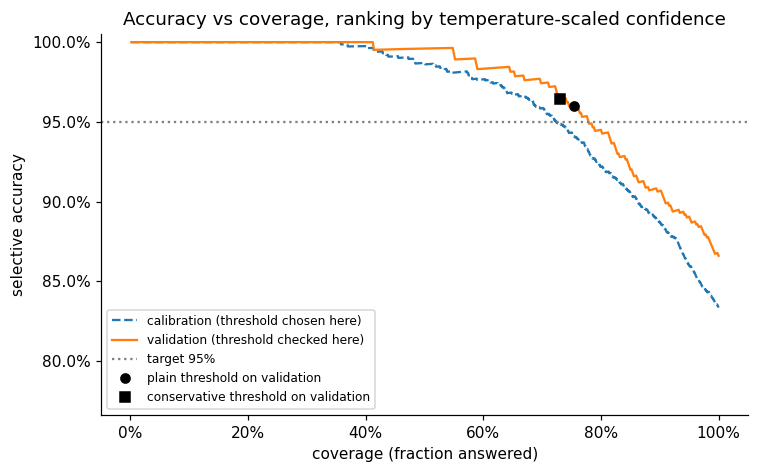

In [18]:
fig, ax = plt.subplots(figsize=(7, 4.4))
for name, conf, corr, style in [("calibration (threshold chosen here)", cal_confidence, cal_correct, "--"),
                                ("validation (threshold checked here)", scaled_confidence, correct, "-")]:
    _, answered, hits = selective_curve(conf, corr)
    ax.plot(answered / len(conf), hits / answered, style, label=name)
ax.axhline(TARGET_ACCURACY, ls=":", color="gray", label=f"target {TARGET_ACCURACY:.0%}")
for (rule, threshold), marker in zip(thresholds.items(), ["o", "s"]):
    if threshold is not None:
        answered = scaled_confidence >= threshold
        ax.plot(answered.mean(), correct[answered].mean(), marker, color="black", label=f"{rule} threshold on validation")
ax.set(xlabel="coverage (fraction answered)", ylabel="selective accuracy", ylim=(max(0, correct.mean() - 0.1), 1.005),
       title="Accuracy vs coverage, ranking by temperature-scaled confidence")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

### The most confident mistakes

The wrong validation predictions the model was most sure about, after temperature scaling.

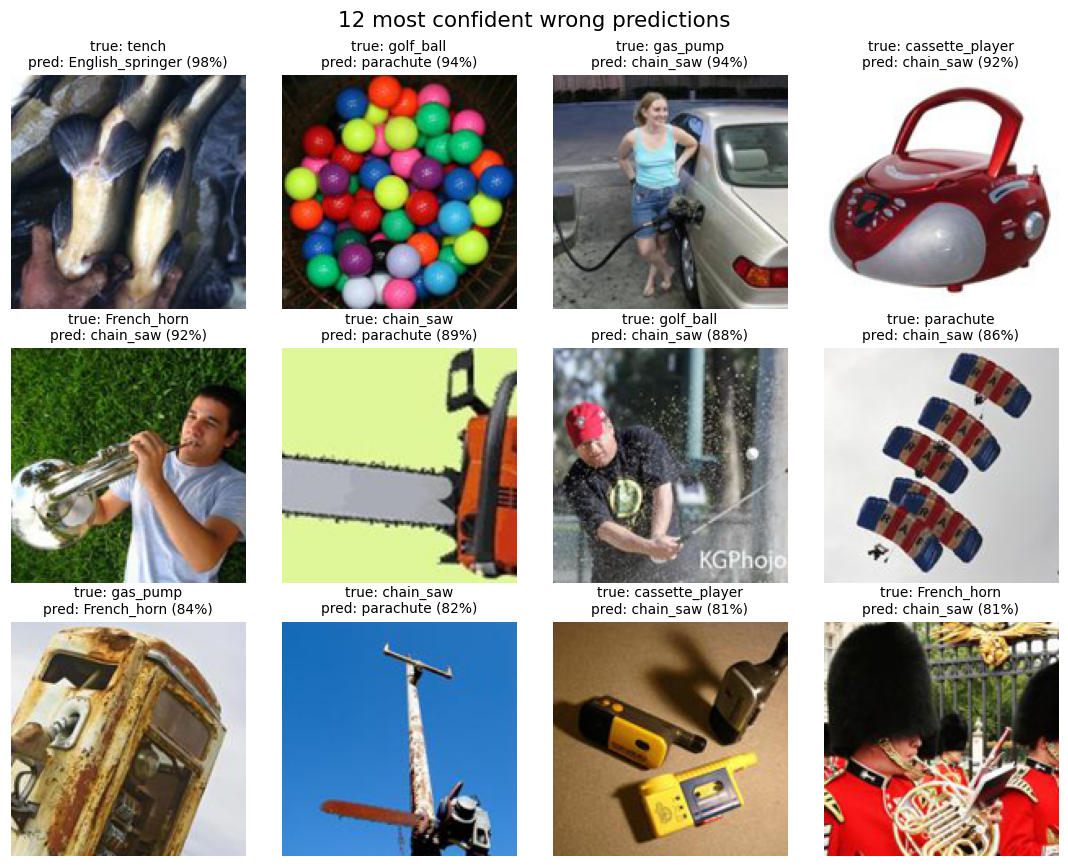

In [19]:
mistakes = np.flatnonzero(~correct)
worst = mistakes[np.argsort(-scaled_confidence[mistakes])][:12]

fig, axes = plt.subplots(3, 4, figsize=(10, 8))
for ax in axes.flat:
    ax.axis("off")
for ax, i in zip(axes.flat, worst):
    ax.imshow(x_val[i].transpose(1, 2, 0))
    ax.set_title(f"true: {class_names[y_true[i]]}\npred: {class_names[y_pred[i]]} ({scaled_confidence[i]:.0%})", fontsize=9)
fig.suptitle(f"{len(worst)} most confident wrong predictions", fontsize=14)
plt.tight_layout()
plt.show()

## 12. Save the model and its outputs

The same files as notebook 04, in `outputs/` (ignored by Git): the checkpoint (weights, normalization statistics, settings, split indices, temperature, thresholds) and the validation and calibration outputs with the same keys as notebook 04. Notebook 09 loads them.

In [20]:
OUTPUT_DIR = Path("../outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

torch.save({
    "model_state": model.state_dict(),
    "channel_mean": channel_mean.cpu(),
    "channel_std": channel_std.cpu(),
    "class_names": class_names,
    "wnids": wnids,
    "split_indices": {"train": train_idx, "validation": val_idx, "calibration": cal_idx},
    "temperature": TEMPERATURE,
    "thresholds": thresholds,
    "settings": {"seed": SEED, "val_per_class": VAL_PER_CLASS, "cal_per_class": CAL_PER_CLASS, "epochs": EPOCHS, "batch_size": BATCH_SIZE, "max_lr": MAX_LR,
                 "weight_decay": WEIGHT_DECAY, "target_accuracy": TARGET_ACCURACY, "store_size": STORE_SIZE, "crop_size": CROP_SIZE, "stem": STEM},
    "history": history.to_dict(),
}, OUTPUT_DIR / f"{MODEL_NAME}.pt")


def save_outputs(path, logits, embeddings, targets, indices):
    np.savez_compressed(
        path, logits=logits.numpy(), probabilities=logits.softmax(1).numpy(), embeddings=embeddings.numpy(),
        targets=targets, predictions=logits.argmax(1).numpy(), class_names=np.array(class_names), dataset_indices=indices,
    )

save_outputs(OUTPUT_DIR / f"{MODEL_NAME}_validation_outputs.npz", val_logits, val_embeddings, y_val, val_idx)
save_outputs(OUTPUT_DIR / f"{MODEL_NAME}_calibration_outputs.npz", cal_logits, cal_embeddings, y_cal, cal_idx)
print("Saved:", *sorted(p.name for p in OUTPUT_DIR.iterdir() if p.name.startswith(MODEL_NAME)), sep="\n  ")

Saved:
  imagenette_resnet18.pt
  imagenette_resnet18_calibration_outputs.npz
  imagenette_resnet18_validation_outputs.npz


## 13. Optional: final check on the test set

Run this only once the model and every setting are final; set `EVALUATE_TEST = True` at the top. It applies the temperature and thresholds fitted on the calibration set, unchanged, to the 3,925 images of Imagenette's `val` folder.

In [21]:
if EVALUATE_TEST:
    test_images, _ = to_device(x_test, y_test)
    test_logits, test_embeddings = predict(test_images)
    test_correct = test_logits.argmax(1).numpy() == y_test
    test_raw = softmax_confidence(test_logits)
    test_scaled = softmax_confidence(test_logits, TEMPERATURE)
    print(f"test accuracy {test_correct.mean():.1%}  |  ECE before {calibration_bins(test_raw, test_correct)[2]:.1%}, "
          f"after temperature scaling {calibration_bins(test_scaled, test_correct)[2]:.1%}")
    display(pd.DataFrame({f"{rule}, checked on test": check_threshold(threshold, test_scaled, test_correct)
                          for rule, threshold in thresholds.items()}).T)
    save_outputs(OUTPUT_DIR / f"{MODEL_NAME}_test_outputs.npz", test_logits, test_embeddings, y_test, np.arange(len(y_test)))
else:
    print("Skipped: the test set stays untouched (set EVALUATE_TEST = True to run).")

Skipped: the test set stays untouched (set EVALUATE_TEST = True to run).


## 14. Questions for the team

1. How large is the gap between training and validation accuracy? Smaller than CIFAR-100's (99.3% against 72%)?
2. Which classes get confused? Do the mistakes look like true errors or ambiguous images?
3. What temperature was fitted, and how much did it reduce the ECE?
4. What coverage does the softmax threshold reach at 95% selective accuracy? That is the number SDM needs to beat in notebook 09.